# Домашнее задание 1. Message passing своими руками

**ФИО:** `Арзуманов Олег Анатольевич`  
**Группа:** `s4202`  

##### Все пункты задания выполнены

## Подготовка окружения

In [ ]:
%pip -q install pytest torch torch_geometric

import sys
import torch.nn.functional as F
from torch_geometric.datasets import Planetoid
from torch_geometric.utils import subgraph

import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from warnings import filterwarnings
filterwarnings('ignore')

## Часть 1. Реализация и проверка — 2 балла

- [x] Реализуйте `MyGCNConv` — слой GCN из лекции 3, через scatter-операции.
- [x] Реализуйте `MySAGEConv` — mean-агрегация соседей плюс отдельная матрица
      для собственного вектора вершины (без петель).
- [x] Положите оба класса в `submission.py` и прогоните автотесты:

```bash
pip install pytest torch torch_geometric
pytest tests/test_task1.py -v
```

- [x] Приложите вывод тестов в ноутбук. **Работа без прохождения тестов не принимается.**

Тесты проверяют совпадение с `GCNConv` и `SAGEConv` из PyG при одинаковых весах,
инвариантность к перенумерации вершин, поведение на направленном графе и на
вершинах без соседей.

In [2]:
#%%writefile tests/submission.py
import torch
import torch.nn as nn
from torch_geometric.utils import add_remaining_self_loops, scatter


class MyGCNConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.lin = nn.Linear(in_channels, out_channels, bias=False)
        self.bias = nn.Parameter(torch.zeros(out_channels))

    def forward(self, x, edge_index):
        n = x.size(0)
        edge_index, _ = add_remaining_self_loops(edge_index, num_nodes=n)
        row, col = edge_index

        deg = scatter(x.new_ones(col.numel()), col, dim=0, dim_size=n, reduce="sum")
        deg_inv_sqrt = deg.pow(-0.5)
        deg_inv_sqrt.masked_fill_(torch.isinf(deg_inv_sqrt), 0)

        norm = deg_inv_sqrt[row] * deg_inv_sqrt[col]
        x = self.lin(x)

        out = scatter(x[row] * norm.unsqueeze(-1), col, dim=0, dim_size=n, reduce="sum")

        return out + self.bias


class MySAGEConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.lin_neigh = nn.Linear(in_channels, out_channels, bias=False)
        self.lin_self = nn.Linear(in_channels, out_channels, bias=False)

    def forward(self, x, edge_index):
        row, col = edge_index
        neigh_mean = scatter(x[row], col, dim=0, dim_size=x.size(0), reduce="mean")
        
        return self.lin_neigh(neigh_mean) + self.lin_self(x)

### Запуск тестов

In [3]:
from pathlib import Path
import subprocess

TEST = Path("tests/test_task1.py")
if TEST.is_file():
    print("Найден файл:", TEST.resolve())
    proc = subprocess.run(
        [sys.executable, "-m", "pytest", "tests/test_task1.py", "-v"],
        text=True, capture_output=True
    )
    print(proc.stdout)
    if proc.stderr:
        print("STDERR:\n", proc.stderr)
    print("Код завершения pytest:", proc.returncode)
    if proc.returncode != 0:
        raise RuntimeError("Тесты не пройдены.")
else:
    print("tests/test_task1.py не найден.")

Найден файл: C:\Users\oleg\code\graphs\gnn_tasks\tests\test_task1.py
============================= test session starts =============================
platform win32 -- Python 3.12.10, pytest-9.1.1, pluggy-1.7.0 -- c:\Users\oleg\code\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: c:\Users\oleg\code\graphs\gnn_tasks
plugins: anyio-4.15.1, platformdirs-4.13.5
collecting ... collected 7 items

tests/test_task1.py::test_gcn_output_shape PASSED                        [ 14%]
tests/test_task1.py::test_gcn_matches_pyg PASSED                         [ 28%]
tests/test_task1.py::test_gcn_on_directed_graph PASSED                   [ 42%]
tests/test_task1.py::test_gcn_permutation_invariance PASSED              [ 57%]
tests/test_task1.py::test_gcn_isolated_node_is_finite PASSED             [ 71%]
tests/test_task1.py::test_sage_matches_pyg PASSED                        [ 85%]
tests/test_task1.py::test_gcn_is_trainable PASSED                        [100%]

============================== 7 pas

## Часть 2. Воспроизведение результата — 1.5 балла

- [x] Обучите двухслойную модель на своих слоях на **Cora** и **CiteSeer**,
      стандартный сплит Planetoid.
- [x] Каждый замер — **не менее 5 запусков с разными сидами**, в отчёте среднее и
      стандартное отклонение.
- [x] Сравните с числами из статьи Kipf & Welling (2017): Cora 81.5, CiteSeer 70.3.
      Попадание в ± 2 процентных пункта считается воспроизведением.
- [x] Обязательный baseline: MLP того же размера, который не видит графа.
      Насколько граф улучшает результат на каждом датасете?

In [4]:
SEEDS = [13, 17, 23, 37, 42]  # пять различных сидов
HIDDEN = 32
DROPOUT = 0.5
LR = 0.01
WEIGHT_DECAY = 5e-4
MAX_EPOCHS = 400
PATIENCE = 10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

print("Устройство:", DEVICE)
print("Сиды:", SEEDS)
print("PyTorch Geometric:", __import__("torch_geometric").__version__)

DATA_ROOT = "/content/planetoid" if Path("/content").exists() else "./data/planetoid"
datasets = {}
for name in ["Cora", "CiteSeer"]:
    ds = Planetoid(root=DATA_ROOT, name=name, split="public")
    data = ds[0].to(DEVICE)
    datasets[name] = data
    print(
        f"{name}: nodes={data.num_nodes}, edges={data.edge_index.size(1)}, "
        f"features={data.num_node_features}, classes={ds.num_classes}, "
        f"train={int(data.train_mask.sum())}, val={int(data.val_mask.sum())}, "
        f"test={int(data.test_mask.sum())}"
    )

Устройство: cuda
Сиды: [13, 17, 23, 37, 42]
PyTorch Geometric: 2.8.1
Cora: nodes=2708, edges=10556, features=1433, classes=7, train=140, val=500, test=1000
CiteSeer: nodes=3327, edges=9104, features=3703, classes=6, train=120, val=500, test=1000


Для GCN, MLP и GraphSAGE реализованы модели одинаковой глубины: `num_layers` включает последний классификационный слой. В скрытых слоях применяются ReLU и dropout. После выбора эпохи по валидационной маске восстанавливаются лучшие веса; test accuracy вычисляется отдельно.

In [5]:
class GCNClassifier(nn.Module):
    def __init__(self, in_channels, hidden_channels, num_classes, num_layers=2, dropout=0.5):
        super().__init__()

        dims = [in_channels] + [hidden_channels] * (num_layers - 1) + [num_classes]
        self.convs = nn.ModuleList([MyGCNConv(dims[i], dims[i + 1]) for i in range(num_layers)])
        self.dropout = dropout

    def forward(self, x, edge_index, return_hidden=False):
        h = x
        hidden = None
        for i, conv in enumerate(self.convs):
            h = F.dropout(h, p=self.dropout, training=self.training)
            h = conv(h, edge_index)
            if i < len(self.convs) - 1:
                h = F.relu(h)
                hidden = h
        log_probs = F.log_softmax(h, dim=-1)
        
        return (log_probs, hidden) if return_hidden else log_probs


class MLPClassifier(nn.Module):

    def __init__(self, in_channels, hidden_channels, num_classes, num_layers=2, dropout=0.5):
        super().__init__()

        dims = [in_channels] + [hidden_channels] * (num_layers - 1) + [num_classes]
        self.lins = nn.ModuleList([nn.Linear(dims[i], dims[i + 1]) for i in range(num_layers)])
        self.dropout = dropout

    def forward(self, x, edge_index=None, return_hidden=False):
        h = x
        hidden = None
        for i, lin in enumerate(self.lins):
            h = F.dropout(h, p=self.dropout, training=self.training)
            h = lin(h)
            if i < len(self.lins) - 1:
                h = F.relu(h)
                hidden = h
        log_probs = F.log_softmax(h, dim=-1)
        
        return (log_probs, hidden) if return_hidden else log_probs


class SAGEClassifier(nn.Module):
    def __init__(self, in_channels, hidden_channels, num_classes, dropout=0.5):
        super().__init__()
        self.conv1 = MySAGEConv(in_channels, hidden_channels)
        self.conv2 = MySAGEConv(hidden_channels, num_classes)
        self.dropout = dropout

    def forward(self, x, edge_index, return_hidden=False):
        h = F.dropout(x, p=self.dropout, training=self.training)
        h = F.relu(self.conv1(h, edge_index))
        hidden = h
        h = F.dropout(h, p=self.dropout, training=self.training)
        logits = self.conv2(h, edge_index)
        log_probs = F.log_softmax(logits, dim=-1)
        
        return (log_probs, hidden) if return_hidden else log_probs


def build_model(kind, data, num_layers=2):
    common = (data.num_node_features, HIDDEN, int(data.y.max().item()) + 1)
    
    if kind == "gcn":
        return GCNClassifier(*common, num_layers=num_layers, dropout=DROPOUT)
    if kind == "mlp":
        return MLPClassifier(*common, num_layers=num_layers, dropout=DROPOUT)
    if kind == "sage":
        return SAGEClassifier(*common, dropout=DROPOUT)
    
    raise ValueError(f"Неизвестная модель: {kind}")


def accuracy(model, x, edge_index, y, mask):
    model.eval()
    with torch.no_grad():
        log_probs = model(x, edge_index)
        
        return (log_probs[mask].argmax(dim=-1) == y[mask]).float().mean().item()


def fit_model(model, x, edge_index, y, train_mask, val_mask, seed,
              max_epochs=MAX_EPOCHS, patience=PATIENCE):
    set_seed(seed)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    best_state = None
    best_val_acc = -1.0
    best_val_loss = float("inf")
    best_epoch = 0
    patience_left = patience

    for epoch in range(1, max_epochs + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        log_probs = model(x, edge_index)
        loss = F.nll_loss(log_probs[train_mask], y[train_mask])
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_log_probs = model(x, edge_index)
            val_loss = F.nll_loss(val_log_probs[val_mask], y[val_mask]).item()
            val_acc = (val_log_probs[val_mask].argmax(dim=-1) == y[val_mask]).float().mean().item()

        is_better = (val_acc > best_val_acc + 1e-12) or (
            abs(val_acc - best_val_acc) <= 1e-12 and val_loss < best_val_loss - 1e-9
        )
        if is_better:
            best_val_acc = val_acc
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_left = patience
        else:
            patience_left -= 1

        if patience_left <= 0:
            break

    if best_state is None:
        raise RuntimeError("Не удалось сохранить состояние модели")
    
    model.load_state_dict(best_state)
    info = {"best_epoch": best_epoch,
            "epochs_trained": epoch,
            "best_val_acc": best_val_acc,
            "best_val_loss": best_val_loss}
    
    return model, info


def train_one(kind, data, seed, num_layers=2, x=None, edge_index=None,
              y=None, train_mask=None, val_mask=None):

    x = data.x if x is None else x
    edge_index = data.edge_index if edge_index is None else edge_index
    y = data.y if y is None else y
    train_mask = data.train_mask if train_mask is None else train_mask
    val_mask = data.val_mask if val_mask is None else val_mask
    set_seed(seed)
    model = build_model(kind, data, num_layers=num_layers)
    model, info = fit_model(model, x, edge_index, y, train_mask, val_mask, seed)
    
    return model, info

Запускаются GCN и MLP одинаковой ширины на публичном Planetoid split.

In [6]:
main_results = {}
main_models = {}
for name, data in datasets.items():
    main_results[name] = {}
    main_models[name] = {}
    for kind in ["gcn", "mlp"]:
        runs = []
        for seed in SEEDS:
            t0 = time.time()
            model, info = train_one(kind, data, seed, num_layers=2)
            test_acc = accuracy(model, data.x, data.edge_index, data.y, data.test_mask)
            runs.append({
                "seed": seed,
                "test_acc": test_acc,
                "best_val_acc": info["best_val_acc"],
                "best_epoch": info["best_epoch"],
                "epochs_trained": info["epochs_trained"],
                "model": model if (name == "Cora" and kind == "gcn") else None,
            })
            print(f"{name:8s} {kind.upper():3s} seed={seed:2d} "
                  f"test_acc={test_acc*100:6.2f}% best_epoch={info['best_epoch']:3d} "
                  f"time={time.time()-t0:5.1f}s")
        main_results[name][kind] = runs
        main_models[name][kind] = [r["model"] for r in runs if r["model"] is not None]


def mean_std(values):
    values = np.asarray(values, dtype=float)
    mean = float(values.mean())
    std = float(values.std(ddof=1)) if len(values) > 1 else 0.0
    return mean, std


def mean_std_pct(values):
    m, s = mean_std(values)
    return f"{m*100:.2f} ± {s*100:.2f}%"

rows = []
targets = {"Cora": 81.5, "CiteSeer": 70.3}
for name in datasets:
    gcn = [r["test_acc"] for r in main_results[name]["gcn"]]
    mlp = [r["test_acc"] for r in main_results[name]["mlp"]]
    gm, gs = mean_std(gcn)
    mm, ms = mean_std(mlp)
    rows.append({
        "Датасет": name,
        "GCN test accuracy, среднее ± SD": mean_std_pct(gcn),
        "MLP test accuracy, среднее ± SD": mean_std_pct(mlp),
        "Преимущество GCN над MLP, п.п.": f"{(gm-mm)*100:+.2f}",
        "Цель из задания, %": targets[name],
        "В пределах ±2 п.п.": abs(gm*100 - targets[name]) <= 2.0,
    })
main_table = pd.DataFrame(rows)
display(main_table)

print("Сиды и результаты каждого запуска:")
run_rows = []
for name in datasets:
    for kind in ["gcn", "mlp"]:
        for r in main_results[name][kind]:
            run_rows.append({
                "Датасет": name, "Модель": kind.upper(), "seed": r["seed"],
                "test accuracy, %": round(r["test_acc"] * 100, 3),
                "best val accuracy, %": round(r["best_val_acc"] * 100, 3),
                "best epoch": r["best_epoch"], "эпох обучено": r["epochs_trained"],
            })
display(pd.DataFrame(run_rows))

Cora     GCN seed=13 test_acc= 80.50% best_epoch= 23 time=  0.8s
Cora     GCN seed=17 test_acc= 80.20% best_epoch= 20 time=  0.1s
Cora     GCN seed=23 test_acc= 80.60% best_epoch= 26 time=  0.1s
Cora     GCN seed=37 test_acc= 81.10% best_epoch= 19 time=  0.1s
Cora     GCN seed=42 test_acc= 81.00% best_epoch= 18 time=  0.1s
Cora     MLP seed=13 test_acc= 56.50% best_epoch= 26 time=  0.1s
Cora     MLP seed=17 test_acc= 56.50% best_epoch= 17 time=  0.0s
Cora     MLP seed=23 test_acc= 55.40% best_epoch= 30 time=  0.1s
Cora     MLP seed=37 test_acc= 55.80% best_epoch= 23 time=  0.1s
Cora     MLP seed=42 test_acc= 55.00% best_epoch= 24 time=  0.1s
CiteSeer GCN seed=13 test_acc= 68.80% best_epoch= 12 time=  0.1s
CiteSeer GCN seed=17 test_acc= 70.10% best_epoch= 13 time=  0.1s
CiteSeer GCN seed=23 test_acc= 70.20% best_epoch= 12 time=  0.1s
CiteSeer GCN seed=37 test_acc= 71.20% best_epoch= 10 time=  0.1s
CiteSeer GCN seed=42 test_acc= 68.80% best_epoch= 10 time=  0.1s
CiteSeer MLP seed=13 test

,Датасет,"GCN test accuracy, среднее ± SD","MLP test accuracy, среднее ± SD","Преимущество GCN над MLP, п.п.","Цель из задания, %",В пределах ±2 п.п.
0,Cora,80.68 ± 0.37%,55.84 ± 0.67%,+24.84,81.5,True
1,CiteSeer,69.82 ± 1.03%,53.10 ± 1.60%,+16.72,70.3,True


Сиды и результаты каждого запуска:


,Датасет,Модель,seed,"test accuracy, %","best val accuracy, %",best epoch,эпох обучено
0,Cora,GCN,13,80.5,79.8,23,33
1,Cora,GCN,17,80.2,79.0,20,30
2,Cora,GCN,23,80.6,80.0,26,36
3,Cora,GCN,37,81.1,80.0,19,29
4,Cora,GCN,42,81.0,79.2,18,28
5,Cora,MLP,13,56.5,56.6,26,36
6,Cora,MLP,17,56.5,60.6,17,27
7,Cora,MLP,23,55.4,56.8,30,40
8,Cora,MLP,37,55.8,58.0,23,33
9,Cora,MLP,42,55.0,58.8,24,34


## Часть 3. Что ломается при увеличении глубины — 1.5 балла

- [x] Обучите модель с 2, 4, 8 и 16 слоями, постройте график accuracy от глубины.
- [x] Численно измерьте, насколько представления вершин стали похожи друг на друга:
      среднее попарное косинусное сходство скрытого слоя (или Dirichlet energy).
- [x] Постройте график этой величины от числа слоёв рядом с графиком accuracy.
- [x] **Объясните в тексте**, что именно произошло. Различайте два случая: представления
      слиплись (сходство близко к 1) и сеть просто не обучилась (активации занулились).

depth= 4 seed=13 test= 79.20% cos=+0.6905 zero=0.000 mean_norm=12.69 time=0.2s
depth= 4 seed=17 test= 74.80% cos=+0.7033 zero=0.000 mean_norm=11.05 time=0.2s
depth= 4 seed=23 test= 74.60% cos=+0.5946 zero=0.000 mean_norm=12.58 time=0.2s
depth= 4 seed=37 test= 78.90% cos=+0.6855 zero=0.000 mean_norm=10.03 time=0.2s
depth= 4 seed=42 test= 78.80% cos=+0.7086 zero=0.000 mean_norm=10.59 time=0.2s
depth= 8 seed=13 test= 31.60% cos=+0.9975 zero=0.000 mean_norm=0.07292 time=0.1s
depth= 8 seed=17 test= 19.20% cos=+0.9990 zero=0.000 mean_norm=0.396 time=0.2s
depth= 8 seed=23 test= 14.90% cos=+0.9980 zero=0.000 mean_norm=0.04997 time=0.1s
depth= 8 seed=37 test= 15.50% cos=+0.9994 zero=0.000 mean_norm=0.4527 time=0.3s
depth= 8 seed=42 test= 21.40% cos=+0.9992 zero=0.000 mean_norm=0.5457 time=0.3s
depth=16 seed=13 test= 14.90% cos=+0.9959 zero=0.000 mean_norm=0.05313 time=0.2s
depth=16 seed=17 test= 31.10% cos=+0.9992 zero=0.000 mean_norm=0.1242 time=0.3s
depth=16 seed=23 test= 15.00% cos=+0.9994 z

,Число слоёв,"Test accuracy, % (среднее ± SD)",Среднее cosine ± SD,Нулевая доля ± SD,Средняя L2-норма ± SD
0,2,80.68 ± 0.37,0.7218 ± 0.0068,0.000 ± 0.000,5.092 ± 0.455
1,4,77.26 ± 2.34,0.6765 ± 0.0467,0.000 ± 0.000,11.39 ± 1.19
2,8,20.52 ± 6.75,0.9986 ± 0.0008,0.000 ± 0.000,0.3035 ± 0.227
3,16,21.52 ± 8.98,0.9980 ± 0.0014,0.000 ± 0.000,0.1488 ± 0.13


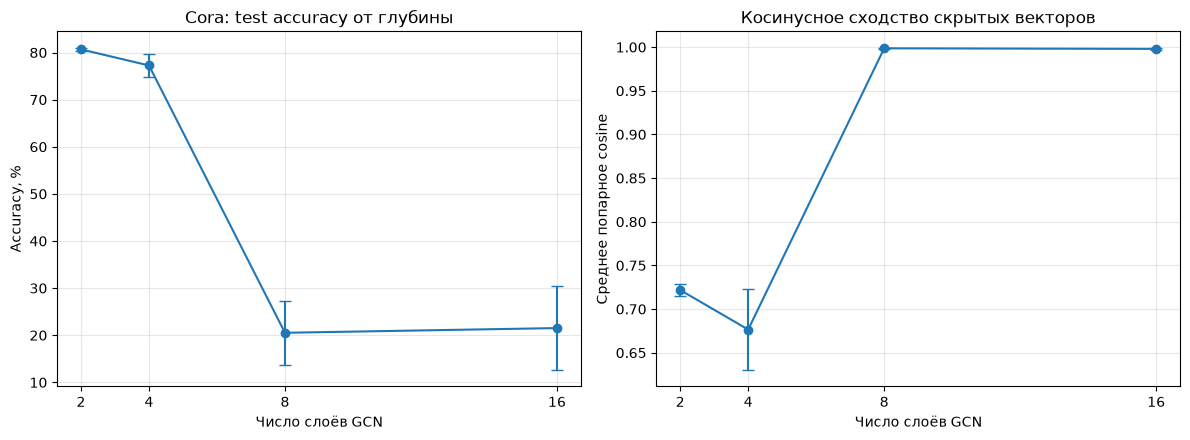

In [7]:
def hidden_diagnostics(model, data, seed, max_nodes=1000):
    model.eval()
    with torch.no_grad():
        _, z = model(data.x, data.edge_index, return_hidden=True)
    norms = z.norm(p=2, dim=1)
    zero_fraction = (norms < 1e-8).float().mean().item()
    mean_norm = norms.mean().item()

    n = z.size(0)
    take = min(max_nodes, n)
    generator = torch.Generator().manual_seed(seed + 9000)
    idx = torch.randperm(n, generator=generator)[:take].to(z.device)
    z_sample = z[idx]
    z_unit = F.normalize(z_sample, p=2, dim=1, eps=1e-12)
    sim = z_unit @ z_unit.T
    non_diag = ~torch.eye(take, dtype=torch.bool, device=z.device)
    mean_cosine = sim[non_diag].mean().item() if take > 1 else float("nan")
    
    return {"cosine": mean_cosine,
            "zero_fraction": zero_fraction,
            "mean_norm": mean_norm}


depth_results = []
data_cora = datasets["Cora"]

for run in main_results["Cora"]["gcn"]:
    model = run["model"]
    diag = hidden_diagnostics(model, data_cora, run["seed"])
    depth_results.append({"depth": 2, "seed": run["seed"], "test_acc": run["test_acc"], **diag})

for depth in [4, 8, 16]:
    for seed in SEEDS:
        t0 = time.time()
        model, info = train_one("gcn", data_cora, seed, num_layers=depth)
        test_acc = accuracy(model, data_cora.x, data_cora.edge_index,
                            data_cora.y, data_cora.test_mask)
        diag = hidden_diagnostics(model, data_cora, seed)
        depth_results.append({
            "depth": depth, "seed": seed, "test_acc": test_acc, **diag
        })
        print(f"depth={depth:2d} seed={seed:2d} test={test_acc*100:6.2f}% "
              f"cos={diag['cosine']:+.4f} zero={diag['zero_fraction']:.3f} "
              f"mean_norm={diag['mean_norm']:.4g} time={time.time()-t0:.1f}s")

depth_df = pd.DataFrame(depth_results)
depth_summary_rows = []
for depth in [2, 4, 8, 16]:
    part = depth_df[depth_df.depth == depth]
    acc_m, acc_s = mean_std(part.test_acc)
    cos_m, cos_s = mean_std(part.cosine)
    zero_m, zero_s = mean_std(part.zero_fraction)
    norm_m, norm_s = mean_std(part.mean_norm)

    depth_summary_rows.append({"Число слоёв": depth,
                               "Test accuracy, % (среднее ± SD)": f"{acc_m*100:.2f} ± {acc_s*100:.2f}",
                               "Среднее cosine ± SD": f"{cos_m:.4f} ± {cos_s:.4f}",
                               "Нулевая доля ± SD": f"{zero_m:.3f} ± {zero_s:.3f}",
                               "Средняя L2-норма ± SD": f"{norm_m:.4g} ± {norm_s:.3g}"})

depth_summary = pd.DataFrame(depth_summary_rows)
display(depth_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
depths = [2, 4, 8, 16]
acc_means, acc_stds, cos_means, cos_stds = [], [], [], []
for depth in depths:
    part = depth_df[depth_df.depth == depth]
    m, s = mean_std(part.test_acc)
    acc_means.append(100*m); acc_stds.append(100*s)
    m, s = mean_std(part.cosine)
    cos_means.append(m); cos_stds.append(s)
axes[0].errorbar(depths, acc_means, yerr=acc_stds, marker="o", capsize=4)
axes[0].set(title="Cora: test accuracy от глубины", xlabel="Число слоёв GCN", ylabel="Accuracy, %")
axes[0].set_xticks(depths); axes[0].grid(alpha=0.3)
axes[1].errorbar(depths, cos_means, yerr=cos_stds, marker="o", capsize=4)
axes[1].set(title="Косинусное сходство скрытых векторов", xlabel="Число слоёв GCN", ylabel="Среднее попарное cosine")
axes[1].set_xticks(depths); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

deepest = depth_df[depth_df.depth == 16]
deep_cos = float(deepest.cosine.mean())
deep_zero = float(deepest.zero_fraction.mean())
deep_norm = float(deepest.mean_norm.mean())

**Вывод**

Эксперимент на датасете Cora показывает, что увеличение глубины GCN сверх нескольких слоёв приводит к резкому снижению качества классификации. Двухслойная модель достигает accuracy 80,68, а четырёхслойная — 77,26. При увеличении глубины до 8 слоёв accuracy падает до 20,52, а у 16-слойной модели составляет 21,52. Для моделей с 8 и 16 слоями среднее попарное косинусное сходство скрытых векторов достигает соответственно 0,9986 и 0,998. Это означает, что представления разных вершин становятся практически коллинеарными, из-за чего модели сложнее различать узлы разных классов.

## Бонус A. Inductive-режим — 2.5 балла

Проверяем, умеет ли модель считать векторы для вершин, которых не видела при обучении.

- [x] Отложите «новые» вершины — 1000 вершин стандартного `test_mask`. Уберите из графа и их
      самих, и все их рёбра (`torch_geometric.utils.subgraph`): получится обучающий подграф.
- [x] **Inductive:** обучите двухслойную модель на `MySAGEConv` только на подграфе. Затем без
      переобучения прогоните её по полному графу — новые вершины приходят вместе со своими
      рёбрами — и посчитайте accuracy на новых вершинах.
- [x] **Transductive:** обучите ту же модель на полном графе — видны все вершины и рёбра, метки
      только у обучающих вершин — и посчитайте accuracy на тех же новых вершинах.
- [x] Сведите результат в таблицу: по 5 сидов на режим, среднее ± стандартное отклонение.

| Режим | Видела ли модель новые вершины при обучении? | Accuracy на новых вершинах |
|---|---|:--:|
| inductive | нет | … ± … |
| transductive | да, но без меток | … ± … |

- [x] Объясните в 2–3 предложениях, насколько дорого обходится то, что модель не видела
      новые вершины, и откуда берётся эта разница.

> **Ловушка:** если обучать на полном графе и просто прятать метки новых вершин, получится
> transductive, а не inductive. В inductive-режиме при обучении не должно быть ни самих новых
> вершин, ни их рёбер.

Для компактности бонус A выполняется на Cora; в обоих режимах используются одни и те же пять сидов.

In [8]:
def run_sage_inductive(data, mode, seed):
    if mode == "inductive":
        keep_mask = ~data.test_mask
        keep_idx = torch.where(keep_mask)[0]
        edge_sub, _ = subgraph(subset=keep_mask, edge_index=data.edge_index,
                               relabel_nodes=True, num_nodes=data.num_nodes)
        x_sub = data.x[keep_mask]
        y_sub = data.y[keep_mask]
        train_sub = data.train_mask[keep_mask]
        val_sub = data.val_mask[keep_mask]

        old_endpoints = keep_idx[edge_sub]
        assert not data.test_mask[old_endpoints].any().item()
        assert x_sub.size(0) == int(keep_mask.sum().item())
        model, info = train_one("sage", data, seed, x=x_sub, edge_index=edge_sub, 
                                y=y_sub, train_mask=train_sub, val_mask=val_sub)

        test_acc = accuracy(model, data.x, data.edge_index, data.y, data.test_mask)
        train_nodes = x_sub.size(0)
        train_edges = edge_sub.size(1)
    elif mode == "transductive":
        model, info = train_one("sage", data, seed)
        test_acc = accuracy(model, data.x, data.edge_index, data.y, data.test_mask)
        train_nodes = data.num_nodes
        train_edges = data.edge_index.size(1)
    else:
        raise ValueError(mode)
    
    return {"mode": mode, "seed": seed, "test_acc": test_acc,
            "best_epoch": info["best_epoch"],
            "nodes_visible_in_training_graph": train_nodes,
            "edges_visible_in_training_graph": train_edges}


cora = datasets["Cora"]
print("Число новых вершин по стандартному test_mask:", int(cora.test_mask.sum().item()))
inductive_runs = []
for mode in ["inductive", "transductive"]:
    for seed in SEEDS:
        row = run_sage_inductive(cora, mode, seed)
        inductive_runs.append(row)
        print(f"{mode:12s} seed={seed:2d} test_accuracy={row['test_acc']*100:6.2f}% "
              f"train_graph=({row['nodes_visible_in_training_graph']} узлов, "
              f"{row['edges_visible_in_training_graph']} рёбер)")

inductive_rows = []
for mode in ["inductive", "transductive"]:
    part = [r for r in inductive_runs if r["mode"] == mode]
    m, s = mean_std([r["test_acc"] for r in part])
    inductive_rows.append({
        "Режим": mode,
        "Видела ли модель новые вершины при обучении?": "нет" if mode == "inductive" else "да, без их меток",
        "Accuracy на новых вершинах, среднее ± SD": f"{m*100:.2f} ± {s*100:.2f}%",
    })
inductive_summary = pd.DataFrame(inductive_rows)
display(inductive_summary)

ind_m = np.mean([r["test_acc"] for r in inductive_runs if r["mode"] == "inductive"])
trans_m = np.mean([r["test_acc"] for r in inductive_runs if r["mode"] == "transductive"])
print(f"Разница transductive − inductive: {(trans_m-ind_m)*100:+.2f} процентного пункта.")

Число новых вершин по стандартному test_mask: 1000
inductive    seed=13 test_accuracy= 79.80% train_graph=(1708 узлов, 4438 рёбер)
inductive    seed=17 test_accuracy= 77.60% train_graph=(1708 узлов, 4438 рёбер)
inductive    seed=23 test_accuracy= 75.60% train_graph=(1708 узлов, 4438 рёбер)
inductive    seed=37 test_accuracy= 78.40% train_graph=(1708 узлов, 4438 рёбер)
inductive    seed=42 test_accuracy= 77.90% train_graph=(1708 узлов, 4438 рёбер)
transductive seed=13 test_accuracy= 78.90% train_graph=(2708 узлов, 10556 рёбер)
transductive seed=17 test_accuracy= 77.20% train_graph=(2708 узлов, 10556 рёбер)
transductive seed=23 test_accuracy= 78.00% train_graph=(2708 узлов, 10556 рёбер)
transductive seed=37 test_accuracy= 78.40% train_graph=(2708 узлов, 10556 рёбер)
transductive seed=42 test_accuracy= 79.70% train_graph=(2708 узлов, 10556 рёбер)


,Режим,Видела ли модель новые вершины при обучении?,"Accuracy на новых вершинах, среднее ± SD"
0,inductive,нет,77.86 ± 1.52%
1,transductive,"да, без их меток",78.44 ± 0.94%


Разница transductive − inductive: +0.58 процентного пункта.


**Вывод**

Небольшая разница показывает, что исключение тестовых вершин из обучающего графа не привело к существенной потере качества - разница между режимами равна 0,58 процентного пункта в пользу трансдуктивного режима. Это соответствует индуктивному сценарию, где модель должна обрабатывать ранее невиданные узлы.

## Бонус B. Сколько разметки нужно графу — 2.5 балла

- [x] Постройте зависимость accuracy от доли размеченных вершин: 1%, 5%, 20%, 60%.
- [x] На одном графике — GCN и MLP.
- [x] Ответьте: при какой доле разметки преимущество графа исчезает и почему.

fraction=   1% (  27 узлов) GCN seed=13 test= 61.25% best_epoch= 20 time=0.1s
fraction=   1% (  27 узлов) MLP seed=13 test= 42.07% best_epoch= 15 time=0.0s
fraction=   5% ( 135 узлов) GCN seed=13 test= 79.52% best_epoch= 21 time=0.1s
fraction=   5% ( 135 узлов) MLP seed=13 test= 55.35% best_epoch= 32 time=0.1s
fraction=  20% ( 542 узлов) GCN seed=13 test= 86.90% best_epoch= 31 time=0.1s
fraction=  20% ( 542 узлов) MLP seed=13 test= 69.19% best_epoch= 30 time=0.1s
fraction=  60% (1625 узлов) GCN seed=13 test= 89.11% best_epoch= 36 time=0.2s
fraction=  60% (1625 узлов) MLP seed=13 test= 78.97% best_epoch= 26 time=0.1s
fraction=   1% (  27 узлов) GCN seed=17 test= 69.19% best_epoch= 28 time=0.1s
fraction=   1% (  27 узлов) MLP seed=17 test= 36.53% best_epoch= 29 time=0.1s
fraction=   5% ( 135 узлов) GCN seed=17 test= 82.47% best_epoch= 35 time=0.2s
fraction=   5% ( 135 узлов) MLP seed=17 test= 52.58% best_epoch= 24 time=0.0s
fraction=  20% ( 542 узлов) GCN seed=17 test= 85.61% best_epoch=

,Доля размеченных вершин,Число меток,Модель,"Test accuracy, среднее ± SD"
0,1%,27,GCN,66.57 ± 3.10%
1,1%,27,MLP,39.48 ± 3.81%
2,5%,135,GCN,80.81 ± 1.46%
3,5%,135,MLP,55.39 ± 3.19%
4,20%,542,GCN,85.98 ± 1.67%
5,20%,542,MLP,68.63 ± 2.28%
6,60%,1625,GCN,89.04 ± 0.79%
7,60%,1625,MLP,77.27 ± 1.13%


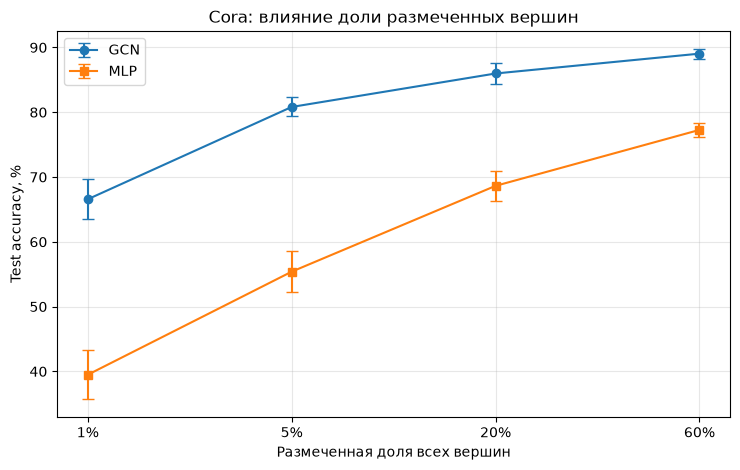

Модель,GCN,MLP,"GCN − MLP, п.п."
Доля размеченных вершин,,,
1%,66.568267,39.483395,27.084872
5%,80.811809,55.387454,25.424355
20%,85.977862,68.634689,17.343173
60%,89.040592,77.269373,11.771219


На четырёх проверенных долях не обнаружено уровня с |GCN−MLP| < 1.0 п.п. и GCN остаётся выше MLP


In [9]:
LABEL_FRACTIONS = [0.01, 0.05, 0.20, 0.60]
LABEL_SEEDS = SEEDS


def make_label_fraction_split(num_nodes, seed, device):
    generator = torch.Generator().manual_seed(seed + 12000)
    perm = torch.randperm(num_nodes, generator=generator)
    n_val = int(round(0.10 * num_nodes))
    n_test = int(round(0.20 * num_nodes))
    val_idx = perm[:n_val]
    test_idx = perm[n_val:n_val+n_test]
    train_pool = perm[n_val+n_test:]

    val_mask = torch.zeros(num_nodes, dtype=torch.bool)
    test_mask = torch.zeros(num_nodes, dtype=torch.bool)
    val_mask[val_idx] = True
    test_mask[test_idx] = True
    return train_pool, val_mask.to(device), test_mask.to(device)


label_runs = []
data = datasets["Cora"]
n = data.num_nodes
for seed in LABEL_SEEDS:
    train_pool, val_mask, test_mask = make_label_fraction_split(n, seed, DEVICE)
    assert not (val_mask & test_mask).any().item()
    for frac in LABEL_FRACTIONS:
        n_labeled = int(round(frac * n))
        if n_labeled > len(train_pool):
            raise ValueError(f"Для {frac:.0%} узлов недостаточно обучающего пула")
        train_idx = train_pool[:n_labeled].to(DEVICE)
        train_mask = torch.zeros(n, dtype=torch.bool, device=DEVICE)
        train_mask[train_idx] = True
        assert not (train_mask & val_mask).any().item()
        assert not (train_mask & test_mask).any().item()

        for kind in ["gcn", "mlp"]:
            t0 = time.time()
            model, info = train_one(kind, data, seed, train_mask=train_mask, val_mask=val_mask)
            test_acc = accuracy(model, data.x, data.edge_index, data.y, test_mask)
            label_runs.append({
                "fraction": frac, "n_labeled": n_labeled, "seed": seed,
                "model": kind, "test_acc": test_acc,
                "best_epoch": info["best_epoch"],
            })
            print(f"fraction={frac:5.0%} ({n_labeled:4d} узлов) {kind.upper():3s} "
                  f"seed={seed:2d} test={test_acc*100:6.2f}% "
                  f"best_epoch={info['best_epoch']:3d} time={time.time()-t0:.1f}s")

label_df = pd.DataFrame(label_runs)
label_summary_rows = []
for frac in LABEL_FRACTIONS:
    for kind in ["gcn", "mlp"]:
        part = label_df[(label_df.fraction == frac) & (label_df.model == kind)]
        m, s = mean_std(part.test_acc)
        label_summary_rows.append({
            "Доля размеченных вершин": f"{frac:.0%}",
            "Число меток": int(part.n_labeled.iloc[0]),
            "Модель": kind.upper(),
            "Test accuracy, среднее ± SD": f"{m*100:.2f} ± {s*100:.2f}%",
            "mean accuracy, %": m*100,
            "SD, п.п.": s*100,
        })
label_summary = pd.DataFrame(label_summary_rows)
display(label_summary.drop(columns=["mean accuracy, %", "SD, п.п."]))

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for kind, marker in [("gcn", "o"), ("mlp", "s")]:
    means, stds = [], []
    for frac in LABEL_FRACTIONS:
        vals = label_df[(label_df.fraction == frac) & (label_df.model == kind)].test_acc.to_numpy()
        m, s = mean_std(vals)
        means.append(m*100); stds.append(s*100)
    ax.errorbar([f"{f:.0%}" for f in LABEL_FRACTIONS], means, yerr=stds,
                marker=marker, capsize=4, label=kind.upper())
ax.set(title="Cora: влияние доли размеченных вершин", xlabel="Размеченная доля всех вершин",
       ylabel="Test accuracy, %")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


label_pivot = label_summary.pivot(index="Доля размеченных вершин", columns="Модель", values="mean accuracy, %")
frac_order = [f"{f:.0%}" for f in LABEL_FRACTIONS]
label_pivot = label_pivot.reindex(frac_order)
label_pivot["GCN − MLP, п.п."] = label_pivot["GCN"] - label_pivot["MLP"]
display(label_pivot)
threshold_pp = 1.0
near_zero = [frac for frac in LABEL_FRACTIONS
             if abs(float(label_pivot.loc[f"{frac:.0%}", "GCN − MLP, п.п."])) < threshold_pp]
nonpositive = [frac for frac in LABEL_FRACTIONS
               if float(label_pivot.loc[f"{frac:.0%}", "GCN − MLP, п.п."]) <= 0.0]
if nonpositive:
    print("На уровне(ях) GCN уже не превосходит MLP: " + ", ".join(f"{f:.0%}" for f in nonpositive) + ".")
elif near_zero:
    print(f"Преимущество практически исчезает при |GCN−MLP| < {threshold_pp:.1f} п.п. на уровне: "
          + ", ".join(f"{f:.0%}" for f in near_zero) + ".")
else:
    print(f"На четырёх проверенных долях не обнаружено уровня с |GCN−MLP| < {threshold_pp:.1f} п.п. и GCN остаётся выше MLP")

**Вывод**

За счет механизма Message Passing GCN эффективно использует топологию графа, что дает заметный прирост к качеству по сравнению с MLP. С увеличением доли размеченных вершин разница в качестве становится менее выраженной, однако преимущество GCN сохраняется, значит структура связей продолжает давать дополнительный сигнал в рамках выбранного разбиения.